In [4]:
# 优化
# 1.不显示错误警告
import warnings
warnings.filterwarnings('ignore')

# 2.画图过程中的中文显示
from matplotlib import pyplot as plt
plt.rcParams['font.family'] = ['sans-serif']
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False     # 修复负号显示问题

图片已保存为: E:\gaussian file\相关性分析_14指标_横向SCI版.png


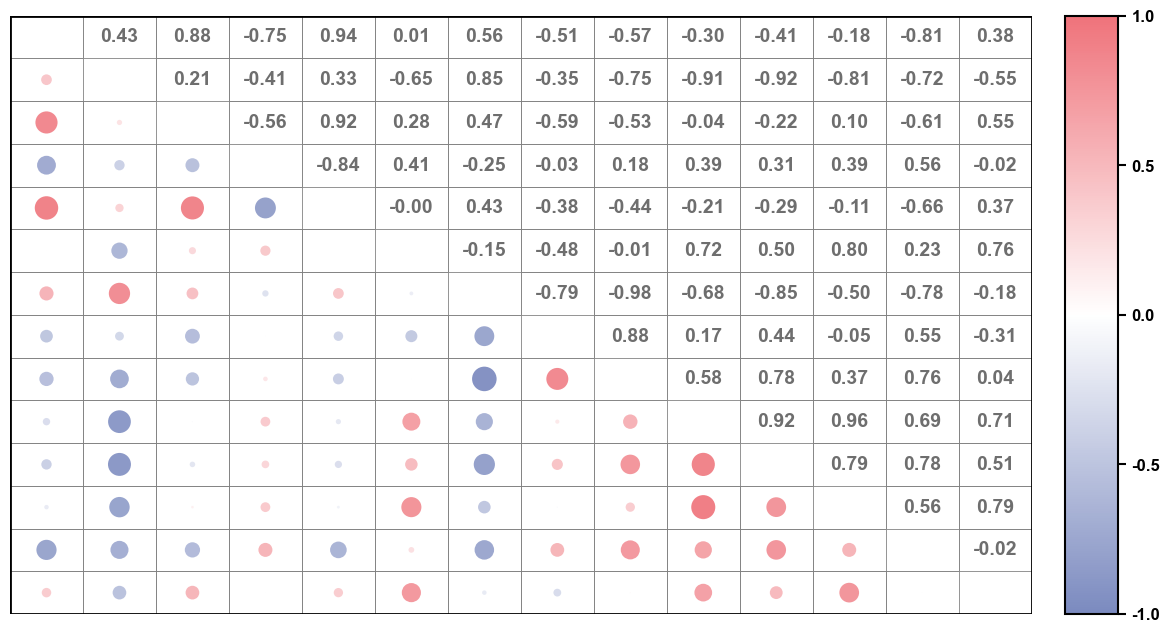

In [5]:
# ================================
# SCI最终优化版（14指标）
# 横向加宽 + 高度压缩版本
#
# 修改内容：
# 1. 整体横向更宽
# 2. 整体纵向稍微压缩
# 3. 圆形气泡居中
# 4. 色度条与主框等高
# 5. SCI论文风格优化
# ================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle, Circle
from pandas import read_csv

# ================================
# 导入数据（14指标）
# ================================
filename = r'E:\gaussian file\相关性分析2.csv'

names = [
    'MPI',
    'ΔE',
    'ESPmax',
    'ESPmin',
    'ΔESP',
    'H',
    'L',
    'χ',
    'ω',
    'V',
    'A+',
    'A-',
    'A0',
    'Ap'
]

dataset = read_csv(
    filename,
    names=names,
    sep=',',
    header=None
)

# ================================
# 全局参数
# ================================
fontsize = 14
fontweight = 'semibold'
text_color = '#6E6E6E'

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['axes.unicode_minus'] = False

# ================================
# 相关矩阵
# ================================
corr_matrix = dataset.corr(method='pearson')

n_features = len(names)

# ================================
# 方格尺寸（横向加宽）
# ================================
cell_width = 1.40
cell_height = 0.82

# ================================
# 画布（横向SCI比例）
# ================================
fig = plt.figure(figsize=(12.5, 6.8))

gs = fig.add_gridspec(
    1,
    2,
    width_ratios=[24, 1.2],
    wspace=0.03
)

ax_main = fig.add_subplot(gs[0, 0])

# ================================
# 坐标范围
# ================================
x_max = n_features * cell_width - cell_width / 2
y_max = n_features * cell_height - cell_height / 2

ax_main.set_xlim(-cell_width / 2, x_max)
ax_main.set_ylim(-cell_height / 2, y_max)

ax_main.set_aspect('equal')

ax_main.invert_yaxis()

ax_main.set_xticks([])
ax_main.set_yticks([])

# ================================
# 去除默认边框
# ================================
for spine in ax_main.spines.values():
    spine.set_visible(False)

# ================================
# 内部网格线
# ================================
for i in range(1, n_features):

    ax_main.axvline(
        i * cell_width - cell_width / 2,
        color='gray',
        linewidth=0.5,
        alpha=0.7,
        zorder=0
    )

for i in range(1, n_features):

    ax_main.axhline(
        i * cell_height - cell_height / 2,
        color='gray',
        linewidth=0.5,
        alpha=0.7,
        zorder=0
    )

# ================================
# 自定义色图
# ================================
colors = [
    (123/255, 138/255, 191/255),
    (1, 1, 1),
    (239/255, 115/255, 123/255)
]

cmap = LinearSegmentedColormap.from_list(
    "custom_blue_white_red",
    colors,
    N=256
)

norm = mpl.colors.Normalize(vmin=-1, vmax=1)

# ================================
# 绘制矩阵
# ================================
for i in range(n_features):

    for j in range(n_features):

        corr_value = corr_matrix.iloc[i, j]

        x = j * cell_width
        y = i * cell_height

        # =========================
        # 对角线
        # =========================
        if i == j:

            rect = Rectangle(
                (
                    x - cell_width / 2,
                    y - cell_height / 2
                ),
                cell_width,
                cell_height,
                facecolor='white',
                edgecolor='gray',
                linewidth=0.5
            )

            ax_main.add_patch(rect)

        # =========================
        # 左下三角（圆形气泡）
        # =========================
        elif i > j:

            rect = Rectangle(
                (
                    x - cell_width / 2,
                    y - cell_height / 2
                ),
                cell_width,
                cell_height,
                fill=False,
                edgecolor='gray',
                linewidth=0.5
            )

            ax_main.add_patch(rect)

            # =====================
            # 颜色映射
            # =====================
            if corr_value < 0:

                t = abs(corr_value)

                r = 1 - t * (1 - 123/255)
                g = 1 - t * (1 - 138/255)
                b = 1 - t * (1 - 191/255)

            else:

                t = corr_value

                r = 1 - t * (1 - 239/255)
                g = 1 - t * (1 - 115/255)
                b = 1 - t * (1 - 123/255)

            color = (r, g, b)

            # =====================
            # 圆形气泡
            # =====================
            radius = abs(corr_value) * 0.24

            circle = Circle(
                (x, y),
                radius=radius,
                facecolor=color,
                edgecolor='none',
                alpha=0.95
            )

            ax_main.add_patch(circle)

        # =========================
        # 右上三角（数字）
        # =========================
        else:

            rect = Rectangle(
                (
                    x - cell_width / 2,
                    y - cell_height / 2
                ),
                cell_width,
                cell_height,
                fill=False,
                edgecolor='gray',
                linewidth=0.5
            )

            ax_main.add_patch(rect)

            ax_main.text(
                x,
                y,
                f"{corr_value:.2f}",
                ha='center',
                va='center',
                color=text_color,
                fontsize=fontsize,
                fontweight=fontweight,
                fontname='Arial'
            )

# ================================
# 外边框
# ================================
outer_lw = 2

outer_rect = Rectangle(
    (
        -cell_width / 2,
        -cell_height / 2
    ),
    n_features * cell_width,
    n_features * cell_height,
    fill=False,
    edgecolor='black',
    linewidth=outer_lw,
    joinstyle='miter',
    antialiased=True,
    zorder=20
)

ax_main.add_patch(outer_rect)

# ================================
# 色度条
# ================================
ax_colorbar = fig.add_subplot(gs[0, 1])

cbar = mpl.colorbar.ColorbarBase(
    ax_colorbar,
    cmap=cmap,
    norm=norm,
    orientation='vertical'
)

# ================================
# 色度条高度匹配主图
# ================================
fig.canvas.draw()

pos_main = ax_main.get_position()
pos_cbar = ax_colorbar.get_position()

ax_colorbar.set_position([
    pos_cbar.x0,
    pos_main.y0,
    pos_cbar.width,
    pos_main.height
])

# ================================
# 色度条边框
# ================================
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(1.5)

# ================================
# 色度条刻度
# ================================
cbar.ax.tick_params(
    labelsize=12,
    width=1.5,
    length=6,
    direction='out'
)

cbar.set_ticks([
    -1,
    -0.5,
    0,
    0.5,
    1
])

cbar.set_ticklabels([
    '-1.0',
    '-0.5',
    '0.0',
    '0.5',
    '1.0'
])

for label in cbar.ax.get_yticklabels():

    label.set_fontname('Arial')
    label.set_fontsize(12)
    label.set_fontweight('semibold')

# ================================
# 布局
# ================================
fig.subplots_adjust(
    left=0.04,
    right=0.94,
    bottom=0.08,
    top=0.96
)

# ================================
# 保存
# ================================
output_filename = (
    r'E:\gaussian file\相关性分析_14指标_横向SCI版.png'
)

plt.savefig(
    output_filename,
    dpi=600,
    format='png'
)

print(f"图片已保存为: {output_filename}")

# ================================
# 显示
# ================================
plt.show()